# Imports and Setup

In [1]:
%load_ext autoreload

import logging
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s') # NOTSET, DEBUG, INFO, WARN, ERROR, CRITICAL

import os
import numpy as np

os.environ["JAX_PLATFORM_NAME"] = "cpu"  # must be set before importing jax

import jax
import jax.numpy as jnp
from jax import vmap, jit, grad, jacfwd

# Optional: higher numeric accuracy (do this before heavy JAX use)
# try:
#     from jax import config as jax_config
#     jax_config.update("jax_enable_x64", True)
# except Exception:
#     pass

import skewerjax as sjx

import matplotlib as mpl
from matplotlib.collections import LineCollection
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.ticker as mticker
plt.style.use('tableau-colorblind10')
font, rcnew = sjx.config.setup_matplotlib.matplotlib_default_config()
plt.rc('font', **font)
plt.rcParams.update(rcnew)
%matplotlib widget
# %matplotlib inline

INFO:2026-06-16 10:35:34,601:jax._src.xla_bridge:752: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
2026-06-16 10:35:34,601 - INFO - Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
2026-06-16 10:35:34,782 - INFO - SkewerBundle class definition complete


In [2]:
from skewerjax.skewers.skewers import SkewerBundle
from skewerjax.cosmology.cosmology import Cosmology

from skewerjax.fields.fields import ScalarField, VectorField, Fields
import skewerjax.fields.toy_model_samplers as toy_samplers
import skewerjax.utils.aux as aux
import skewerjax.utils.plotting_tools as pt
import skewerjax.utils.plotting_tools_3D_fields as pt3D_fields

import skewerjax.optical_depth.optical_depth as od

from skewerjax.constants.physical_constants import phys

# Cosmology

In [3]:
# Create cosmology object
cosmology = Cosmology(H0=phys.H0, Omega_r_0=0.0, Omega_m_0=1.0, Omega_k_0=0.0, Omega_lambda_0=0.0)
# Define which cosmology to use, this is set as default to 0 since skewer and cosmology objects can deal with multiple cosmologies at once, 
# but other classes such as fields and optical depth are currently only set up for a single cosmology at a time
ii_cosmology = 0

In [4]:
L_box = 110.7  # Mpc
z_box = 2.0

N_grid_skewers = 6
N_ppsk = 4096
N_v = 5000

# Lines

In [5]:
line_bundle = sjx.constants.lines.LineBundle(["HI-LyA", "SiIII-1206"], ref_line_id = "HI-LyA") # "SiIII-1206", "SiII-1190", "SiII-1193" # "HI-LyA-1206", "HI-LyA-1193", "HI-LyA-1190"

# Fields

### Dirac delta poissonian absorvers

In [6]:
N_absorvers = 5
Delta_absorption = 1.2 * (L_box / N_ppsk)

n0_HI = 5e-10
T0_HI = 1.5*10**4

n0_SiIII = n0_HI
T0_SiIII = T0_HI

n0_SiII = n0_HI
T0_SiII = T0_HI

fields = Fields({
    "HI": {
        "temperature": ScalarField(toy_samplers.periodic_top_hat_absorber_sampler(N_absorvers=N_absorvers, Delta=Delta_absorption, C_low=1e-5, C0=T0_HI, L_box=L_box, base_seed=0)),    # UNITS: [K]
        "number_density": ScalarField(toy_samplers.periodic_top_hat_absorber_sampler(N_absorvers=N_absorvers, Delta=Delta_absorption, C_low=1e-20, C0=n0_HI, L_box=L_box, base_seed=0)), # [cm^-3]
        "velocity": VectorField(toy_samplers.velocity_sampler(0.0, 0.0, L_box)),        # UNITS: [km/s]
        "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),         # UNITS: [km/s]
        "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0))        # UNITS: [GHz]
    },
    "SiIII": {
        "temperature": ScalarField(toy_samplers.periodic_top_hat_absorber_sampler(N_absorvers=N_absorvers, Delta=Delta_absorption, C_low=1e-5, C0=T0_SiIII, L_box=L_box, base_seed=0)),    # UNITS: [K]
        "number_density": ScalarField(toy_samplers.periodic_top_hat_absorber_sampler(N_absorvers=N_absorvers, Delta=Delta_absorption, C_low=1e-20, C0=n0_SiIII, L_box=L_box, base_seed=0)), # [cm^-3]
        "velocity": VectorField(toy_samplers.velocity_sampler(0.0, 0.0, L_box)),        # UNITS: [km/s]
        "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),         # UNITS: [km/s]
        "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0))        # UNITS: [GHz]
    },
    # "SiII": {
    #     "temperature": ScalarField(toy_samplers.periodic_top_hat_absorber_sampler(N_absorvers=N_absorvers, Delta=Delta_absorption, C_low=1e-5, C0=T0_SiII, L_box=L_box, base_seed=0)),    # UNITS: [K]
    #     "number_density": ScalarField(toy_samplers.periodic_top_hat_absorber_sampler(N_absorvers=N_absorvers, Delta=Delta_absorption, C_low=1e-20, C0=n0_SiII, L_box=L_box, base_seed=0)), # [cm^-3]
    #     "velocity": VectorField(toy_samplers.velocity_sampler(0.0, 0.0, L_box)),        # UNITS: [km/s]
    #     "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),         # UNITS: [km/s]
    #     "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0))        # UNITS: [GHz]
    # },
})

### Gaussian Random Field 

In [7]:
T0_HI = 1.5*10**4
T0_Si = T0_HI

n0_min = 1e-16
n0_max = 1e-10

def pk_template(k: jnp.ndarray, A, n, k0, k_cut):
    # P(k) = A (k/k0)^n exp[-(k/k_cut)^2]
    kk = jnp.maximum(k, 1e-12)
    return A * (kk / k0) ** n * jnp.exp(-(kk / k_cut) ** 2)
number_density_sampler = toy_samplers.number_density_sampler_gaussian_3d(
    key=jax.random.PRNGKey(0),
    pk_of_k=lambda k: pk_template(k, A=5.0, n=-2.5, k0=2.0, k_cut=50.0),
    n0_min=n0_min, n0_max=n0_max, L_box=L_box,
    grid_shape=(256, 256, 256), contrast=1.2,
)
fields = Fields({
    "HI": {
        "temperature": ScalarField(toy_samplers.temperature_sampler(T0_HI, T0_HI, L_box)),    # UNITS: [K]
        "velocity": VectorField(toy_samplers.velocity_sampler(0.0, 0.0, L_box)),        # UNITS: [km/s]
        "number_density": ScalarField(number_density_sampler),                          # [cm^-3]
        "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),         # UNITS: [km/s]
        "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0))        # UNITS: [GHz]
    },
    "SiIII": {
        "temperature": ScalarField(toy_samplers.temperature_sampler(T0_Si, T0_Si, L_box)),    # UNITS: [K]
        "velocity": VectorField(toy_samplers.velocity_sampler(0.0, 0.0, L_box)),        # UNITS: [km/s]
        "number_density": ScalarField(number_density_sampler),                          # [cm^-3]
        "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),         # UNITS: [km/s]
        "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0))        # UNITS: [GHz]
    },
    # "SiII": {
    #     "temperature": ScalarField(toy_samplers.temperature_sampler(T0_Si, T0_Si, L_box)),    # UNITS: [K]
    #     "velocity": VectorField(toy_samplers.velocity_sampler(0.0, 0.0, L_box)),        # UNITS: [km/s]
    #     "number_density": ScalarField(number_density_sampler),                          # [cm^-3]
    #     "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),         # UNITS: [km/s]
    #     "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0))        # UNITS: [GHz]
    # },
})

# Skewers

In [8]:
points_grid_skewers = aux.make_skewer_grid_points(L_box, N_grid_skewers, N_ppsk, direction="y", half_shift=True)
points = jnp.reshape(points_grid_skewers, (N_grid_skewers**2, N_ppsk, 3))

skewer_bundle = SkewerBundle(spatial_points=points, cosmologies=cosmology, a0=1/(1+z_box), x0=L_box)

2026-06-16 10:35:39,775 - INFO - Initializing SkewerBundle with 36 skewers, 4096 points per skewer
2026-06-16 10:35:39,802 - INFO - Broadcasting scalar ICs_defined_at_index=-1 to all 36 skewers
2026-06-16 10:35:39,813 - INFO - All skewers set to absorption mode
2026-06-16 10:35:39,849 - INFO - Computing los_directions automatically from spatial coordinate differences
2026-06-16 10:35:39,993 - INFO - Computing comoving distances along skewer direction
2026-06-16 10:35:40,105 - INFO - Computing scale factors from cosmology
2026-06-16 10:35:42,526 - INFO - Storing quadri-vectors
2026-06-16 10:35:42,563 - INFO - SkewerBundle initialization complete


### plot fields

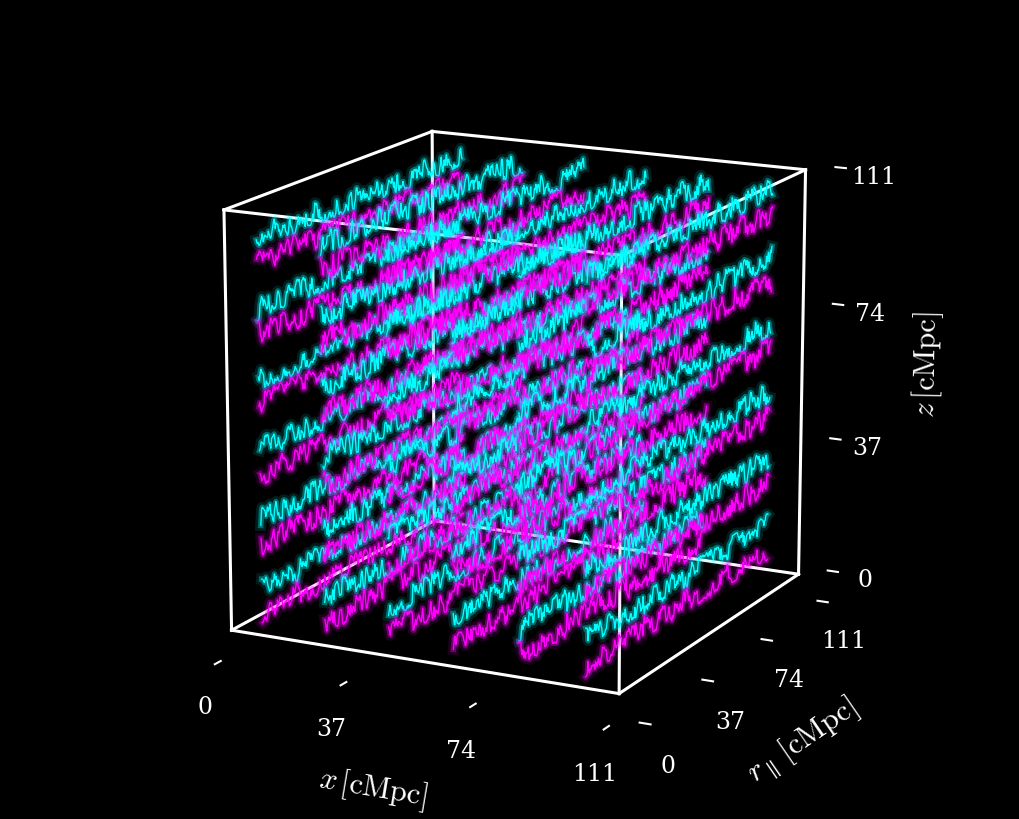

In [9]:
# --- sample the full box once ---
cloud = pt3D_fields.sample_box_cloud(
    skewer_bundle.quadri_vectors[ii_cosmology, 0],  # any skewer for the scale factor
    fields.number_density, box_size=L_box,          # must match the box_size below
    component=0,                                    # 0 = HI
    n=150,                                          # nodes/side: 48→110k pts, 64→260k pts
    a_index=0, xyz_index=(1, 2, 3), log10=True,
)

# --- your original plot call, one argument added ---
sampled_fields = fields.sample(skewer_bundle.quadri_vectors[ii_cosmology], skewer_bundle.los_directions)
plot_dict = {key: jnp.log10(sampled_fields[key]['number_density']) for key in sampled_fields.keys()}

fig, ax = pt3D_fields.plot_3d_neon_ridge_cube(
    points=points, y_dict=plot_dict, normalization="global", field_logscale=False, normalize_scales=False,
    x_label=r"$x\,[{\rm cMpc}]$", y_label=r"$r_{\parallel}\,[{\rm cMpc}]$", z_label=r"$z\,[{\rm cMpc}]$",
    axis_label_fontsize=22, x_label_pad=25.0, y_label_pad=25.0, z_label_pad=25.0,
    n_axis_ticks=(4, 4, 4), ridge_scale=1.0, box_size=L_box, elev=15, azim=-63,
    surrounding_field=None
)

# Optical depth

In [10]:
a_dagger = 1 / (1 + z_box)
a_em = skewer_bundle.scale_factors[0, 0, 0]
v_max = phys.c_kms * jnp.log(a_dagger / a_em)
velocities_kms = jnp.linspace(0, v_max, N_v)
dv = np.diff(velocities_kms)[0]

In [11]:
tau = od.OpticalDepthCalculator(skewer_bundle=skewer_bundle, velocities_kms=velocities_kms, line_bundle=line_bundle, fields=fields, a_dagger=a_dagger, debug_memory=True)
tau.compute()
tau.wrap_to_ref_line()
optical_depth = tau.optical_depth

2026-06-16 10:35:47,096 - INFO - [OPTICAL_DEPTH] initialized in compute mode: N_lines=2, N_species=2, N_sk=36, N_ppsk=4096, N_v=5000.
2026-06-16 10:35:47,097 - INFO - 
[OPTICAL_DEPTH][MEM] initialized
  Process RSS : 1.753 / 125.607 GB  [░░░░░░░░░░░░░░░░░░░░░░░░░░░░]   1.4%
  System RAM  : used=7.274 GB, available=118.333 GB  [██░░░░░░░░░░░░░░░░░░░░░░░░░░]   5.8%
  Change      : ΔRSS=first checkpoint
2026-06-16 10:35:47,097 - INFO - [OPTICAL_DEPTH] start: ii_cosmology=0, voigt=ExoJAX
2026-06-16 10:35:47,098 - INFO - 
[OPTICAL_DEPTH][MEM] loaded quadri_vectors
  Process RSS : 1.753 / 125.607 GB  [░░░░░░░░░░░░░░░░░░░░░░░░░░░░]   1.4%
  System RAM  : used=7.274 GB, available=118.333 GB  [██░░░░░░░░░░░░░░░░░░░░░░░░░░]   5.8%
  Change      : ΔRSS=+0.000 GB
  Array       : shape=(36, 4096, 4), dtype=float32, nbytes=0.002 GB  [░░░░░░░░░░░░░░░░░░░░░░░░░░░░]   0.0%
2026-06-16 10:35:58,851 - INFO - 
[OPTICAL_DEPTH][MEM] after compute_line_profiles
  Process RSS : 12.107 / 125.607 GB  [███░░░░░░░

In [12]:
# # THIS IS JUST A TOY MODEL FOR CHECKING WHAT HAPPENS WHEN THE OPTICAL DEPTH HAS A SINGLE PEAK, IT IS NOT SUPPOSED TO BE PHYSICALLY REALISTIC
# N_sk = skewer_bundle.N_sk
# peak_indices = jax.random.randint(jax.random.PRNGKey(0), shape=(N_sk,), minval=0, maxval=N_v)
# toy_optical_depth = jnp.zeros((N_sk, N_v), dtype=jnp.float32)
# toy_optical_depth = 100 * toy_optical_depth.at[jnp.arange(N_sk), peak_indices].set(1.0)
# toy_optical_depth = jnp.tile(toy_optical_depth[jnp.newaxis, :], (2, 1, 1))
# # Periodically wrap by hand the second entry by `shift_pixels` pixels
# shift_pixels = int(line_bundle.delta_v[1] / dv) 
# toy_optical_depth = toy_optical_depth.at[1].set(jnp.roll(toy_optical_depth[1], shift=shift_pixels, axis=-1))
# tau = sjx.optical_depth.optical_depth.OpticalDepthCalculator(optical_depth=toy_optical_depth, velocities_kms=velocities_kms, line_bundle=line_bundle)
# # tau.wrap_to_ref_line()
# optical_depth = tau.optical_depth
# optical_depth = optical_depth * jnp.array([1.0, 8e-3])[:, jnp.newaxis, jnp.newaxis]

### Plot optical depth

In [13]:
ii_skewer = 0
colors = pt3D_fields._neon_colors(line_bundle.species_keys)
linestyles = ['-', '--', ':', '-.']

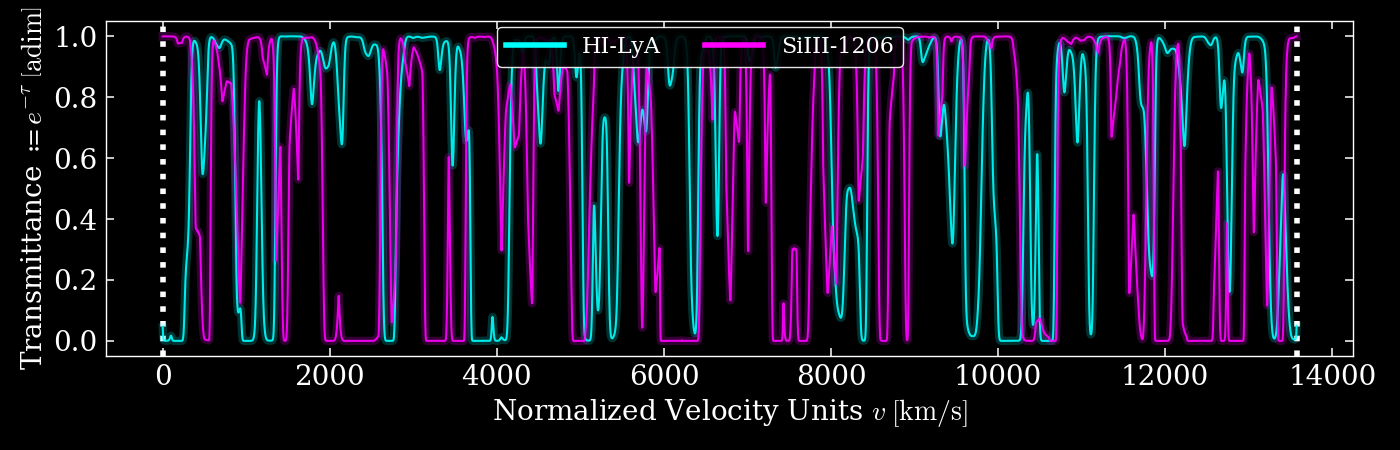

In [14]:
fig, ax = plt.subplots(1, 1, figsize=(14, 4.5), sharex=True, sharey=True, facecolor="black")
ax.set_facecolor("black")

kk = 0
handles = []
for ii, key_species in enumerate(line_bundle.species_keys):
    color = colors[key_species]
    for jj, key_line in enumerate(line_bundle.lines_for_species(key_species)):
        ls = linestyles[jj]
        
        ax.plot(velocities_kms, jnp.exp(-optical_depth[kk, ii_skewer]), color=color, lw=6, ls=ls, alpha=0.2, zorder=2)
        ax.plot(velocities_kms, jnp.exp(-optical_depth[kk, ii_skewer]), color=color, lw=1.5, ls=ls, alpha=0.9, zorder=3)
        
        handles.append(Line2D([0], [0], color=color, lw=4, ls=ls, label=line_bundle.lines[kk].id))
        kk += 1
        
ax.axvline(0, color='white', lw=4, ls=':', zorder=1)
ax.axvline(phys.c_kms*jnp.log(a_dagger / a_em), color='white', lw=4, ls=':', zorder=2)
        
leg = fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.965), ncols=min(len(handles), 7),
    frameon=True, fontsize=16, handlelength=2.6, facecolor="black", edgecolor="white", framealpha=0.9,
)
for text in leg.get_texts():
    text.set_color("white")
        
ax.tick_params(axis="both",  which="major", labelsize=20, colors="white", length=6, width=1.1)
for side in ["top", "right", "bottom", "left"]:
    ax.spines[side].set_color("white")
    ax.spines[side].set_linewidth(1.0)
    
ax.set_ylabel(r"Transmittance $\coloneq e^{-\tau} \; \left[\mathrm{adim}\right]$", fontsize=20, color="white")
ax.set_xlabel(r"Normalized Velocity Units $v \; \left[\mathrm{km}/\mathrm{s}\right]$", fontsize=20, color="white")

fig.tight_layout()
plt.show()

# Overflux

In [15]:
overflux = sjx.optical_depth.overflux.DeltaFieldBuilder(optical_depth).build()

2026-06-16 10:36:06,171 - INFO - Initialized DeltaFieldBuilder with 2 lines, N_samples=36, N_points=5000.
2026-06-16 10:36:06,171 - INFO - Starting build().
2026-06-16 10:36:06,445 - INFO - Finished build(): N_samples=36, subset_keys=3, composite_keys=1.


# 1D summary stats

In [16]:
delta_v_list = list(np.array(line_bundle.delta_v))
velocity_domain = np.max(tau.velocities_kms) - np.min(tau.velocities_kms)
stats = sjx.summary_stats.P1D_xi1D.OverfluxStatistics1D(overflux, dv)
ordered_pairs = stats.ordered_pairs

# $P 1D$

In [17]:
for ii, key in enumerate(overflux.delta_terms):
    print(f"Term {ii}, pair {ordered_pairs[ii]}, delta term shape: {overflux.delta_terms[key].shape}")
    print(f"Number of points per side of the grid: {int(overflux.delta_terms[key].shape[0] ** (1/2))}")

Term 0, pair ('1', '1'), delta term shape: (36, 5000)
Number of points per side of the grid: 6
Term 1, pair ('1', '2'), delta term shape: (36, 5000)
Number of points per side of the grid: 6
Term 2, pair ('1', '12'), delta term shape: (36, 5000)
Number of points per side of the grid: 6


In [18]:
stats.compute_p1d()

Pk_total_from_terms = stats.Pk_total_from_terms

Pk_total_per_sample = stats.Pk_total_per_sample
Pk_total = stats.Pk_total

Pk_pair_per_sample = stats.Pk_pair_per_sample
Pk_pair = stats.Pk_pair

k = stats.k

Angular wavenumber: $k_m = 2\pi f_m = \frac{2\pi m}{N_v dv}$

/home/dlopez/Documentos/0.profesional/Postdoc/USP/Projects/SkewerJAX/skewerjax/utils/plotting_tools_P1D_xi1D.py:633: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


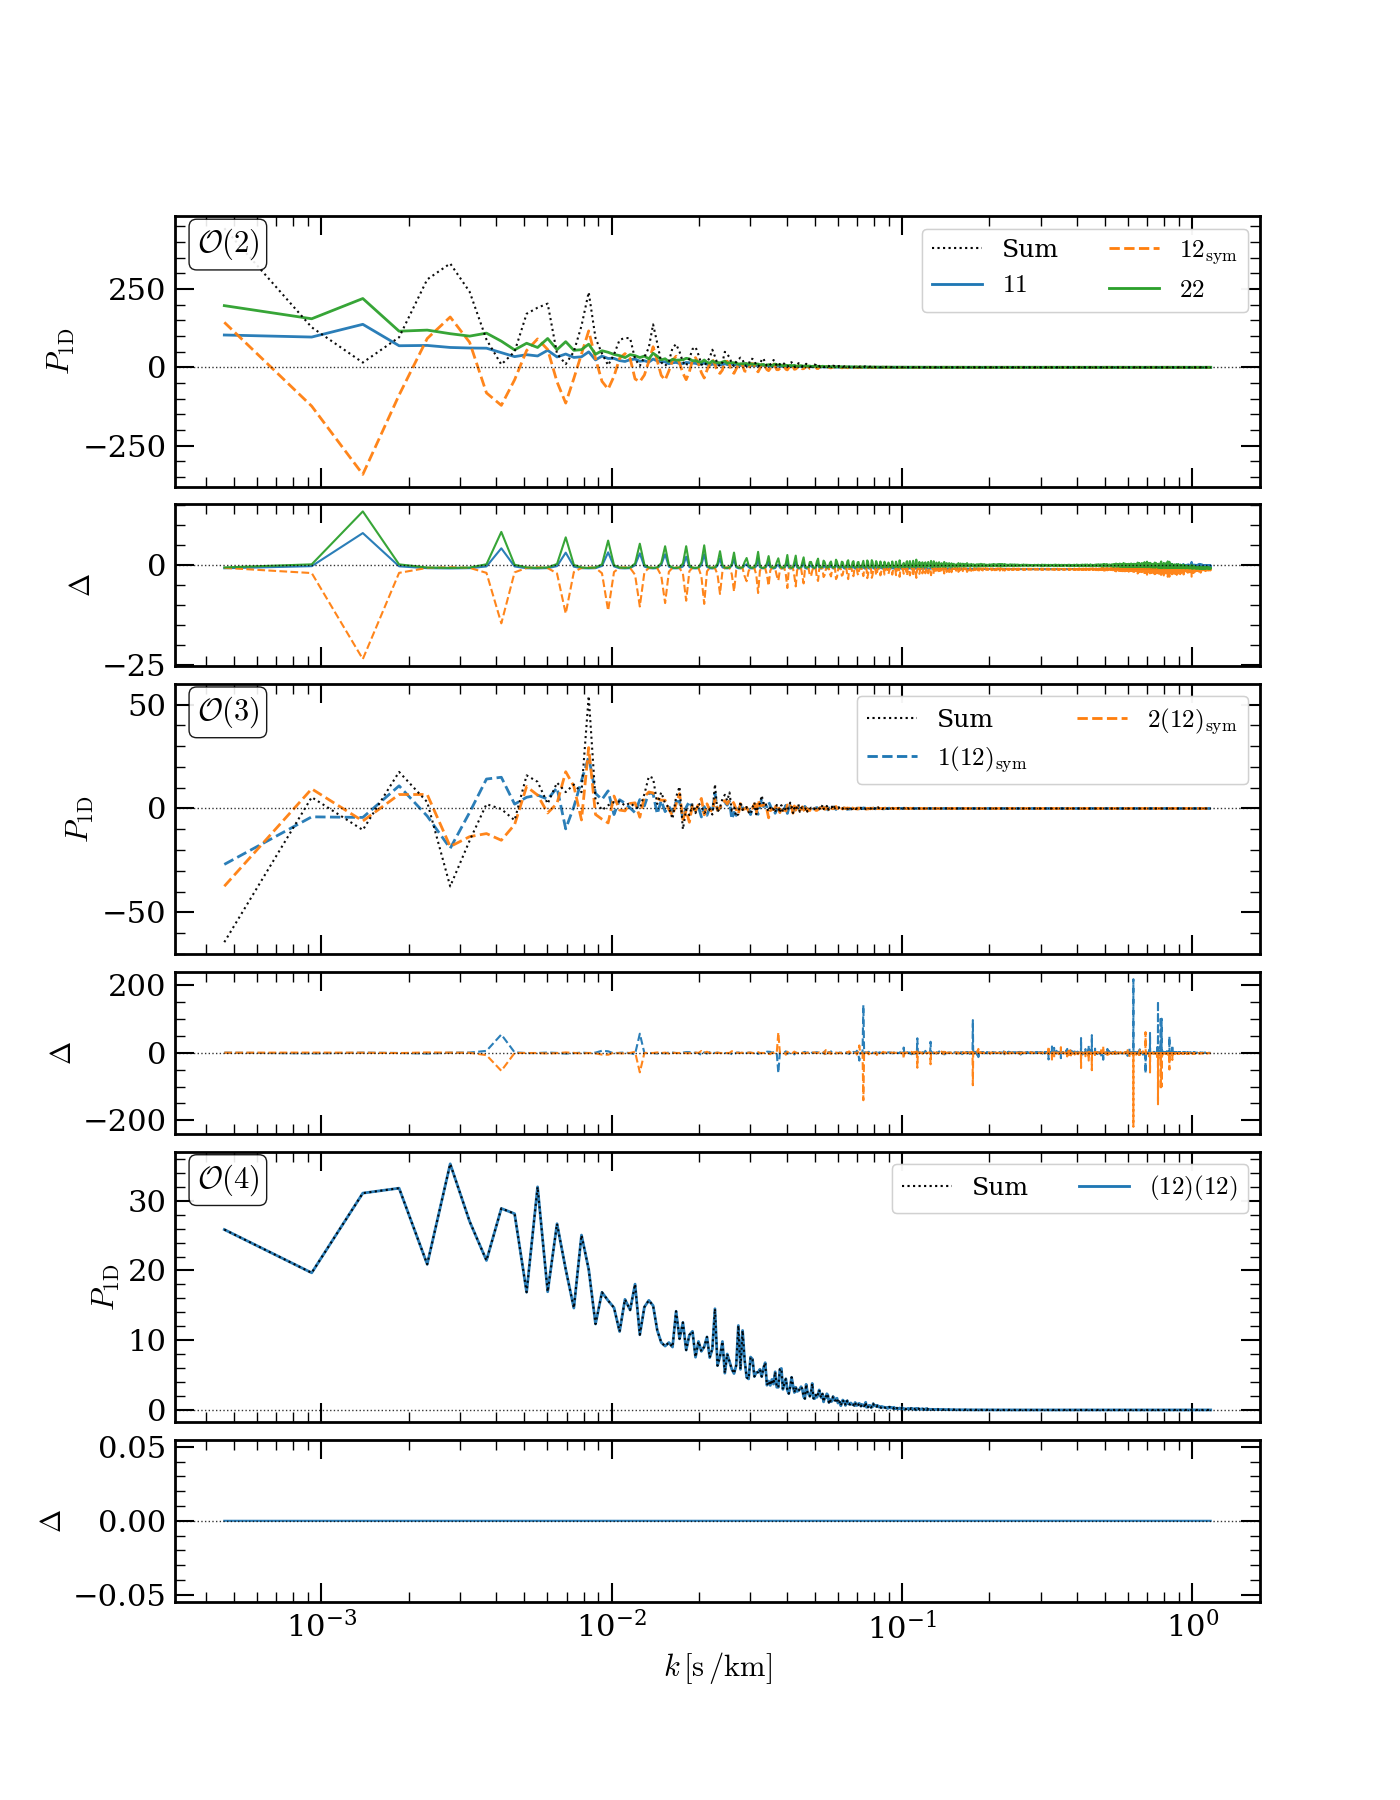

/home/dlopez/Documentos/0.profesional/Postdoc/USP/Projects/SkewerJAX/skewerjax/utils/plotting_tools_P1D_xi1D.py:784: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


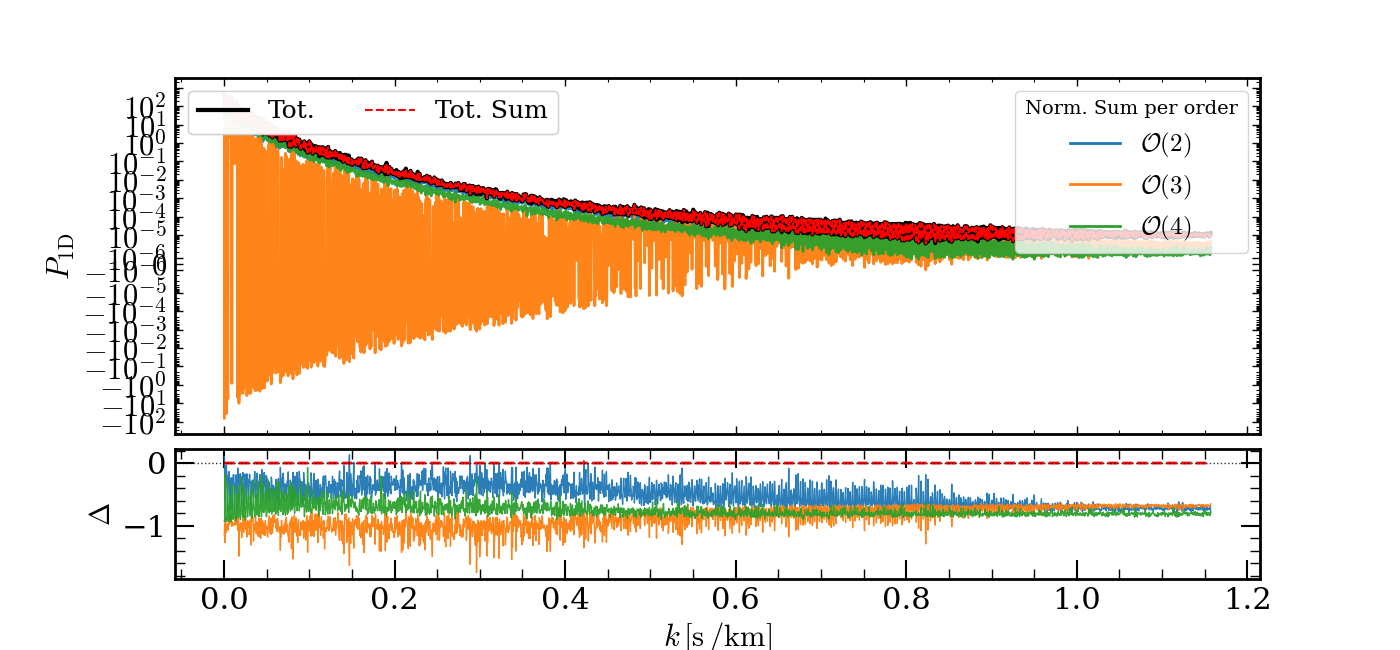

In [19]:
fig, axes, axes_res, order_sum_dict = sjx.utils.plotting_tools_P1D_xi1D.plot_p1d_by_order(
    ordered_pairs=ordered_pairs, Pk_pair=Pk_pair, k=k, delta_v_list=delta_v_list, L_box=velocity_domain, Npix=tau.N_v,
    tolerance_threshold=1e-6, use_log_x=True, # xlim=(2.0, 600),
    residual_mode="sum", show_harmonics=False, use_symlog_main=False, use_symlog_residual=False,
    symlog_linscale=1.0, symlog_label_minor=False, symlog_sci_cutoff=1e-2, legend_ncol_terms=2,
    xlabel=r"$k\,[{\rm s\,/km}]$", ylabel=r"$P_{\rm 1D}$", residual_ylabel=r"$\Delta$",
)

fig, (ax, ax_res), order_sum_dict = sjx.utils.plotting_tools_P1D_xi1D.plot_p1d_total_recovery(
    Pk_total=Pk_total, Pk_total_from_terms=Pk_total_from_terms, Pk_pair=Pk_pair, k=k, delta_v_list=delta_v_list, L_box=velocity_domain, Npix=tau.N_v,
    ordered_pairs=ordered_pairs, show_harmonics=False, show_order_sums=True, show_order_sum_residuals=True,
    use_symlog_main=True, use_symlog_residual=False, xlabel=r"$k\,[{\rm s\,/km}]$"
)

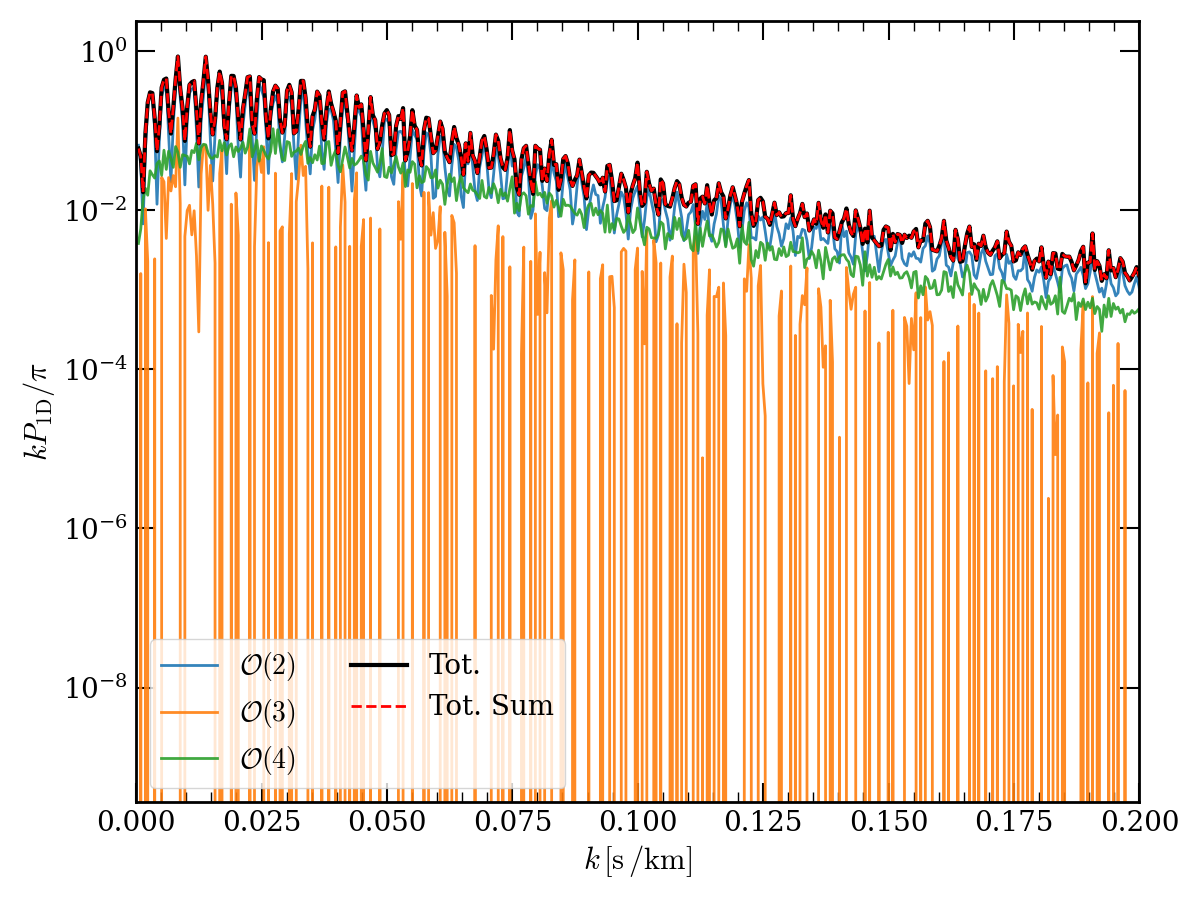

In [20]:
# ===============================================================
# Build order sums from Pk_pair

ordered_pairs = list(Pk_pair.keys()) if ordered_pairs is None else ordered_pairs
order_sum_dict = {}
for pair in ordered_pairs:
    A, B = pair
    order = len(A) + len(B)
    if order not in order_sum_dict:
        order_sum_dict[order] = np.zeros_like(Pk_pair[pair], dtype=float)
    order_sum_dict[order] += Pk_pair[pair].real
orders = sorted(order_sum_dict.keys())

# ===============================================================
# Plot P1D

cmap = plt.get_cmap("tab10")

fig, ax = plt.subplots(figsize=(12, 9))
for i, order in enumerate(orders):
    y_order = order_sum_dict[order][1:] * k[1:] / np.pi
    ax.plot(k[1:], y_order, lw=2.0, color=cmap(i % 10), alpha=0.9, label=rf"$\mathcal{{O}}({order})$")

# Total
ax.plot(k[1:], Pk_total.real[1:] * k[1:] / np.pi, lw=3.0, color="k", label=r"Tot.")

# Total recovered from terms
ax.plot(k[1:], Pk_total_from_terms.real[1:] * k[1:] / np.pi, lw=2.0, color="red", ls="--", label=r"Tot. Sum")

ax.set_yscale("log")

ax.set_xlabel(r"$k\,[{\rm s\,/km}]$", fontsize=22)
ax.set_ylabel(r"$k P_{\rm 1D} / \pi$", fontsize=22)

ax.set_xlim([0.0, 0.2])
# ax.set_ylim([1e-4, 1e-1])

ax.tick_params(axis="both", labelsize=20)
ax.legend(fontsize=20, ncol=2)

plt.tight_layout()
plt.show()

In [21]:
Jonas2026_x = np.asarray([0.0012103424520726075, 0.001710426016737391, 0.0022405113342219723, 0.0026967336406882466, 0.0032317105483064905, 0.003716793236561375, 0.004218507331270713, 0.004720058372975595, 0.005196173145985431, 0.005711909799077935, 0.006196503328319453, 0.006692021408859485, 0.007234824860691589, 0.007707515520607861, 0.00821346899343304, 0.008739967144819602, 0.009207603161597756, 0.009733122994957585, 0.010237935096751576, 0.010697581516311415, 0.011248863724375202, 0.011746175387964242, 0.012217072464831506, 0.01268682817066758, 0.01319946681667543, 0.013692702155153086, 0.01418707886466193, 0.01473575222465443, 0.015217410799815749, 0.01573249524089043, 0.01624921021200967, 0.01672907520412198, 0.01725997578662884, 0.01769777310359165, 0.018203237417403463, 0.01873022472780339, 0.019218568476147384, 0.019730717963141867, 0.020171124128175965, 0.020730558986462522, 0.021214663356690675, 0.021757303755518324, 0.022217928493104895, 0.02264920368988949, 0.023259348032561685, 0.023726331837322017, 0.024201305239300665, 0.024734325510865445, 0.025247616368891116])
Jonas2026_y = np.asarray([0.008702200282951175, 0.010605036156919673, 0.015611253374371708, 0.01789981585681677, 0.020231052528309375, 0.01894901896933219, 0.019569830478807133, 0.02324977718276436, 0.026511191625119498, 0.029135409525467774, 0.02720121897976352, 0.026378752285570163, 0.02845338682745897, 0.032664334384986116, 0.034334887584939515, 0.03291509367959117, 0.03325243646690979, 0.03226665029085164, 0.03275214068403131, 0.0360022415822107, 0.03663308200482874, 0.034491706603143844, 0.0338068641820707, 0.03275361843520383, 0.03600305376965098, 0.03683943699143153, 0.03718343175764788, 0.03466253256400984, 0.035570337794891445, 0.036471463316681864, 0.03717420582883128, 0.03783667637903175, 0.038286596603684, 0.03485464210089554, 0.036262260926746316, 0.03711303718723162, 0.03572393353222253, 0.03583774633183837, 0.03456882478160373, 0.03329146690260813, 0.03444272099734688, 0.03452985467990668, 0.03375885119909169, 0.03508816258046259, 0.03445748710264468, 0.03294778143947462, 0.03183069446317984, 0.0358676721137433, 0.03263340016247513])

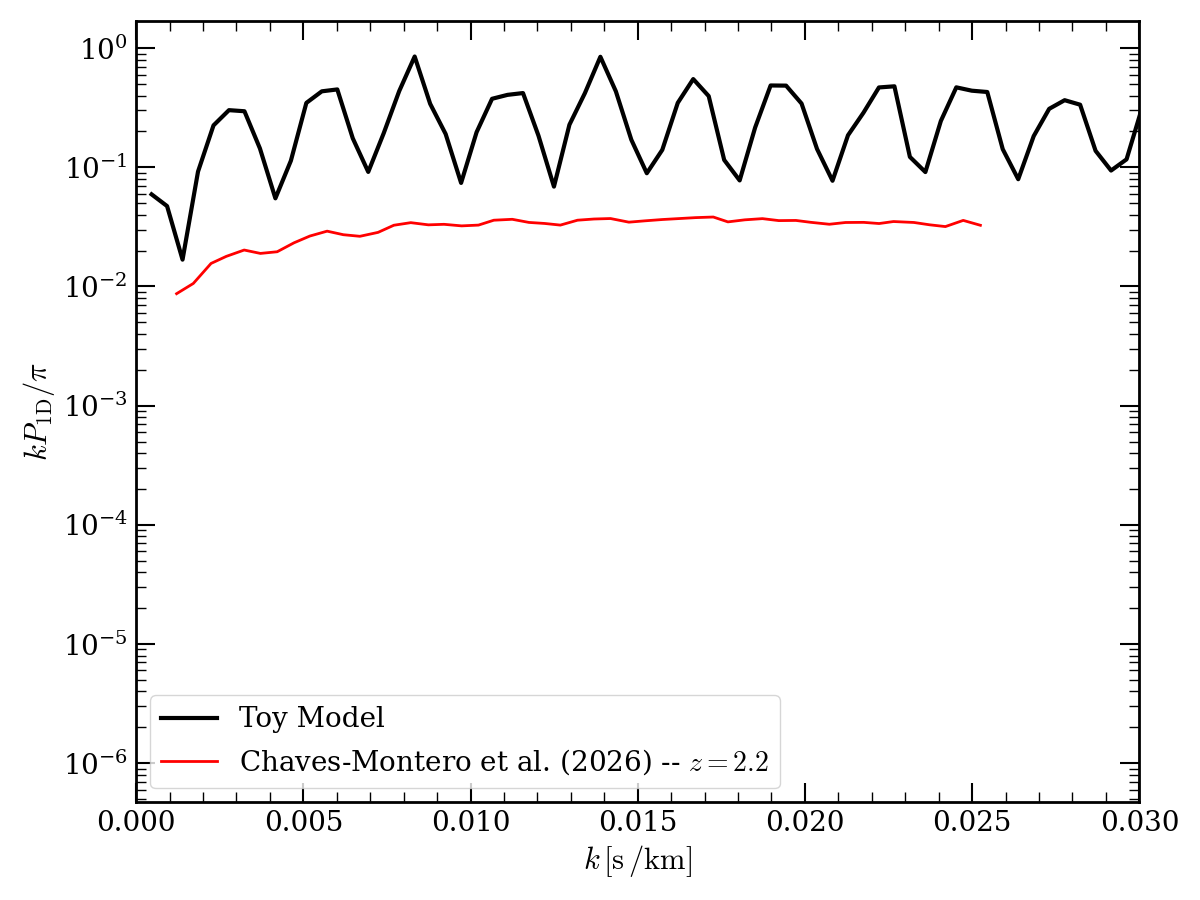

In [22]:
# ===============================================================
# Plot P1D

cmap = plt.get_cmap("tab10")

fig, ax = plt.subplots(figsize=(12, 9))

# Total
ax.plot(k[1:], Pk_total.real[1:] * k[1:] / np.pi, lw=3.0, color="k", label=r"Toy Model")

ax.plot(Jonas2026_x, Jonas2026_y, lw=2.0, color="red", ls="-", label=r"Chaves-Montero et al. (2026) -- $z=2.2$")

ax.set_yscale("log")

ax.set_xlabel(r"$k\,[{\rm s\,/km}]$", fontsize=22)
ax.set_ylabel(r"$k P_{\rm 1D} / \pi$", fontsize=22)

ax.set_xlim([0.0, 0.03])
# ax.set_ylim([0.007, 0.06])

ax.tick_params(axis="both", labelsize=20)
ax.legend(fontsize=20, ncol=1)

plt.tight_layout()
plt.show()

# $\xi 1D$

In [23]:
stats.compute_xi1d()

xi_total_from_terms = stats.xi_total_from_terms

xi_total_per_sample = stats.xi_total_per_sample
xi_total = stats.xi_total

xi_pair_per_sample = stats.xi_pair_per_sample
xi_pair = stats.xi_pair

lags = stats.lags

/home/dlopez/Documentos/0.profesional/Postdoc/USP/Projects/SkewerJAX/skewerjax/utils/plotting_tools_P1D_xi1D.py:978: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


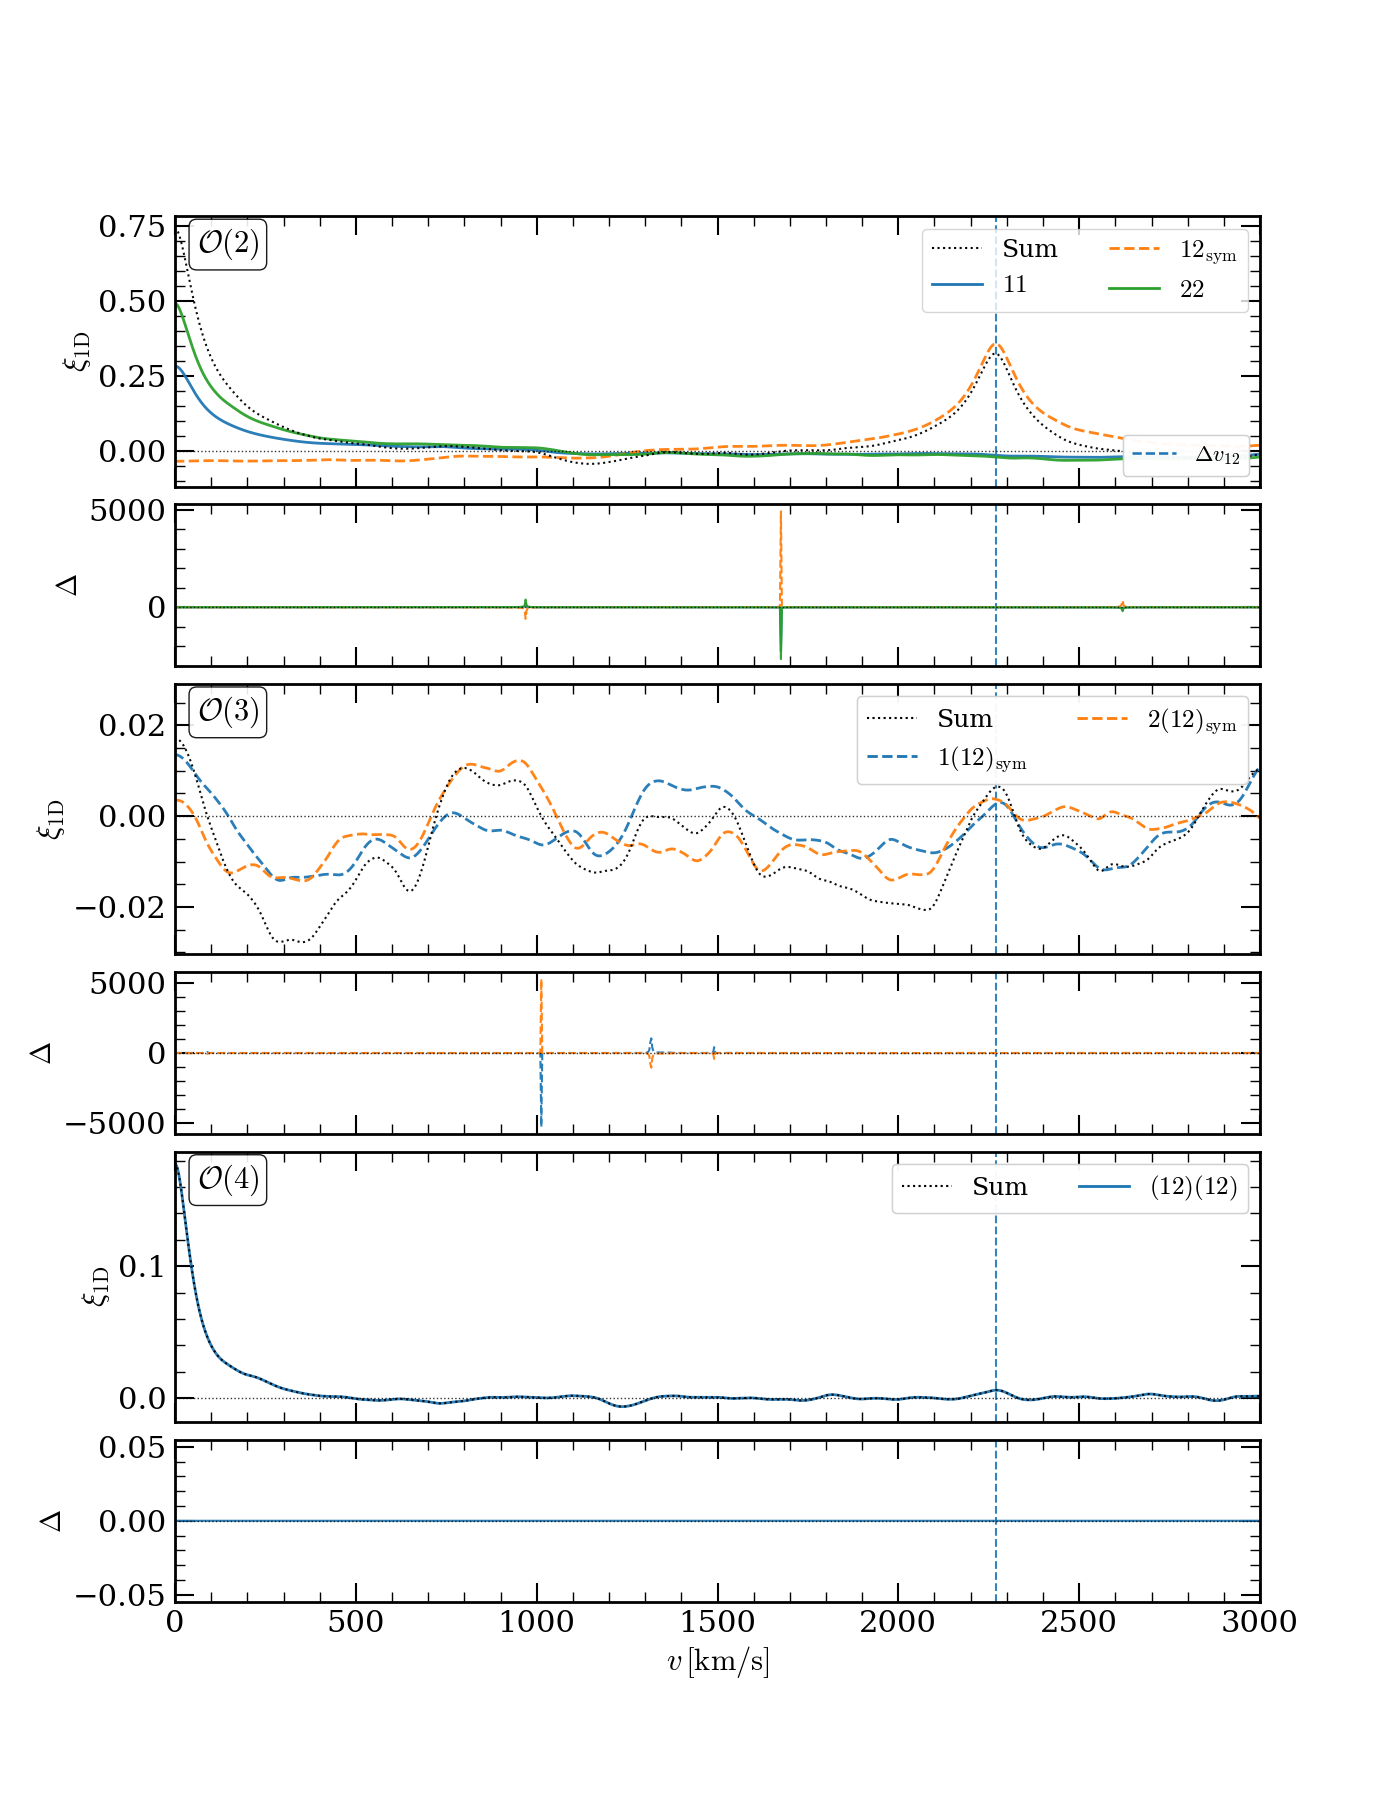

/home/dlopez/Documentos/0.profesional/Postdoc/USP/Projects/SkewerJAX/skewerjax/utils/plotting_tools_P1D_xi1D.py:1137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


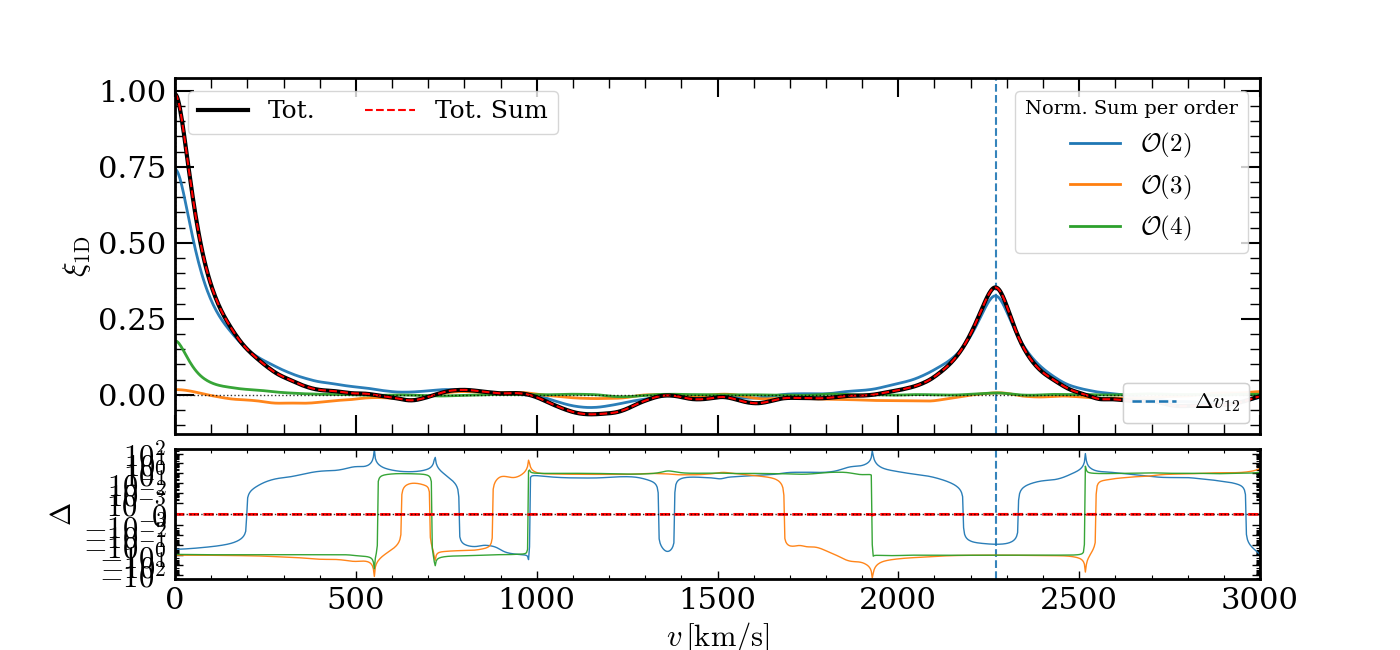

In [24]:
fig, axes, axes_res, xi_order_sum_dict, xi_order_sum_plot_dict = sjx.utils.plotting_tools_P1D_xi1D.plot_xi_by_order(
    ordered_pairs=ordered_pairs, xi_pair=xi_pair, lags=lags, delta_v_list=delta_v_list, L_box=velocity_domain,
    tolerance_threshold=1e-6, residual_mode="sum", show_delta_v_diff_lines=True, use_symlog_main=False,
    use_symlog_residual=False, symlog_linscale=1.0, symlog_base=10, symlog_label_minor=False, symlog_sci_cutoff=1e-2,
    show_order_badge=True, legend_ncol_terms=2, xlabel=r"$v\,\left[{\rm km / s}\right]$", ylabel=r"$\xi_{\rm 1D}$", residual_ylabel=r"$\Delta$",
    xlim=(-0.0, 3000), # xlim=(-0.0, v_max/2)
)

fig, (ax, ax_res), xi_order_sum_dict, xi_order_sum_plot_dict = sjx.utils.plotting_tools_P1D_xi1D.plot_xi_total_recovery(
    xi_total=xi_total, xi_total_from_terms=xi_total_from_terms, xi_pair=xi_pair, lags=lags, delta_v_list=delta_v_list, L_box=velocity_domain, ordered_pairs=ordered_pairs,
    show_order_sums=True, show_order_sum_residuals=True, show_delta_v_diff_lines=True, annotate_half_line=False,
    half_line_text=r"$L_\mathrm{box}/2$", use_symlog_main=False, use_symlog_residual=True, main_symlog_linthresh=None,
    symlog_linscale=1.0, symlog_base=10, symlog_sci_cutoff=1e-2, xlabel=r"$v\,\left[{\rm km / s}\right]$", ylabel=r"$\xi_{\rm 1D}$", residual_ylabel=r"$\Delta$",
    xlim=(-0.0, 3000), # xlim=(-0.0, v_max/2)
)

# 1D Models

In [25]:
from skewerjax.models import models

In [26]:
# ===============================================================
# Input data
# ===============================================================

p_lya = np.asarray(Pk_pair[("1", "1")]).real
p_tot = np.asarray(Pk_total).real

# The sign of Delta v does not matter inside cos(k Delta v).
delta_v_siiii = float(np.abs(np.asarray(line_bundle.delta_v[1])))

k_fit_range = (0.0, 0.1)


# ===============================================================
# Optimizer tolerance parameters
# ===============================================================

mcdonald_optimizer_options = {
    "xatol": 1.0e-14,
    "maxiter": 5000,
}

ma_global_optimizer_options = {
    "tol": 1.0e-10,
    "atol": 1.0e-12,
    "maxiter": 1000,
    "popsize": 25,
    "polish": False,
    "seed": 12345,
    "workers": 1,
    "updating": "immediate",
}

ma_polish_optimizer_options = {
    "maxiter": 50000,
    "ftol": 1.0e-15,
    "gtol": 1.0e-13,
    "maxls": 100,
}


# ===============================================================
# Fit McDonald model
# ===============================================================

fit_mcdonald = models.fit_mcdonald_a(
    k=k,
    p_tot=p_tot,
    p_lya=p_lya,
    delta_v=delta_v_siiii,
    a_bounds=(-10.2, 10.2),
    k_range=k_fit_range,
    fit_mode="ratio",
    optimizer_options=mcdonald_optimizer_options,
)

a_mcd_best = fit_mcdonald["a"]

Pk_mcdonald_best = models.mcdonald_p1d(
    k=k,
    p_lya=p_lya,
    a=a_mcd_best,
    delta_v=delta_v_siiii,
)

ratio_mcdonald_best = models.mcdonald_factor(
    k=k,
    a=a_mcd_best,
    delta_v=delta_v_siiii,
)


# ===============================================================
# Fit Ma et al. profiled model
# ===============================================================

fit_ma = models.fit_ma_model_profiled(
    k=k,
    p_tot=p_tot,
    p_lya=p_lya,
    delta_v=delta_v_siiii,
    k_range=k_fit_range,
    fit_mode="ratio",

    # lambda_auto = 1 / k_auto
    # lambda_cross_abs = 1 / abs(k_cross)
    #
    # The lower bound 0.0 includes the McDonald-like constant limit.
    lambda_bounds={
        "lambda_auto": (0.0, 500.0),
        "lambda_cross_abs": (0.0, 500.0),
    },

    amplitude_bounds={
        "a_auto": (0.0, 100.0),
        "a_cross": (-100.0, 100.0),
    },

    enforce_positive_model=False,
    linear_lsq_tol=1.0e-14,
    run_global=True,
    global_optimizer_options=ma_global_optimizer_options,
    polish_optimizer_options=ma_polish_optimizer_options,
)

a_auto_best = fit_ma["a_auto"]
a_cross_best = fit_ma["a_cross"]
k_auto_best = fit_ma["k_auto"]
k_cross_best = fit_ma["k_cross"]

Pk_ma_auto, Pk_ma_cross, Pk_ma_best = models.ma_components(
    k=k,
    p_lya=p_lya,
    a_auto=a_auto_best,
    a_cross=a_cross_best,
    k_auto=k_auto_best,
    k_cross=k_cross_best,
    delta_v=delta_v_siiii,
)

ratio_ma_best = models.ma_factor(
    k=k,
    a_auto=a_auto_best,
    a_cross=a_cross_best,
    k_auto=k_auto_best,
    k_cross=k_cross_best,
    delta_v=delta_v_siiii,
)

ratio_ma_auto = Pk_ma_auto / p_lya
ratio_ma_cross = Pk_ma_cross / p_lya


# ===============================================================
# Print fit summary
# ===============================================================

print("\nMcDonald fit")
print("============")
print(f"a       = {fit_mcdonald['a']:.8e}")
print(f"chi2    = {fit_mcdonald['chi2']:.8e}")
print(f"N_fit   = {fit_mcdonald['n_fit']}")
print(f"dof     = {fit_mcdonald['dof']}")
print(f"mode    = {fit_mcdonald['fit_mode']}")
print(f"k range = {fit_mcdonald['k_range']}")
print(f"Delta v = {fit_mcdonald['delta_v']:.6f} km/s")
print(f"success = {fit_mcdonald['result'].success}")
print(f"message = {fit_mcdonald['result'].message}")
print(f"xatol   = {mcdonald_optimizer_options['xatol']:.3e}")
print(f"maxiter = {mcdonald_optimizer_options['maxiter']}")

print("\nMa et al. profiled fit")
print("======================")
print(f"a_auto          = {fit_ma['a_auto']:.8e}")
print(f"a_cross         = {fit_ma['a_cross']:.8e}")
print(f"k_auto          = {fit_ma['k_auto']:.8e} s/km")
print(f"k_cross         = {fit_ma['k_cross']:.8e} s/km")
print(f"lambda_auto     = {fit_ma['lambda_auto']:.8e} km/s")
print(f"lambda_crossabs = {fit_ma['lambda_cross_abs']:.8e} km/s")
print(f"chi2            = {fit_ma['chi2']:.8e}")
print(f"N_fit           = {fit_ma['n_fit']}")
print(f"dof             = {fit_ma['dof']}")
print(f"mode            = {fit_ma['fit_mode']}")
print(f"k range         = {fit_ma['k_range']}")
print(f"Delta v         = {fit_ma['delta_v']:.6f} km/s")
print(f"best candidate  = {fit_ma['best_candidate']['label']}")
print(f"linear success  = {fit_ma['lsq_result'].success}")
print(f"linear message  = {fit_ma['lsq_result'].message}")

print("\nModel comparison")
print("================")
print(f"chi2 McDonald = {fit_mcdonald['chi2']:.8e}")
print(f"chi2 Ma       = {fit_ma['chi2']:.8e}")
print(f"Delta chi2    = {fit_ma['chi2'] - fit_mcdonald['chi2']:.8e}")

if fit_ma["chi2"] > fit_mcdonald["chi2"]:
    print("\nWARNING")
    print("=======")
    print("The Ma profiled fit is still worse than McDonald.")
    print("This should not normally happen in ratio mode if:")
    print("  1. lambda_auto = lambda_cross_abs = 0 is allowed,")
    print("  2. a_auto bounds include a_McDonald^2,")
    print("  3. a_cross bounds include 2 a_McDonald,")
    print("  4. enforce_positive_model is False or not excluding the McDonald limit.")


McDonald fit
a       = 2.00621774e+00
chi2    = 9.18487600e+02
N_fit   = 216
dof     = 215
mode    = ratio
k range = (0.0, 0.1)
Delta v = 2269.970947 km/s
success = True
message = Solution found.
xatol   = 1.000e-14
maxiter = 5000

Ma et al. profiled fit
a_auto          = 2.21170518e+00
a_cross         = 2.93957230e+00
k_auto          = 8.26356182e-02 s/km
k_cross         = -1.15513681e+00 s/km
lambda_auto     = 1.21013193e+01 km/s
lambda_crossabs = 8.65698322e-01 km/s
chi2            = 2.83971926e+02
N_fit           = 216
dof             = 212
mode            = ratio
k range         = (0.0, 0.1)
Delta v         = 2269.970947 km/s
best candidate  = local_start
linear success  = True
linear message  = The unconstrained solution is optimal.

Model comparison
chi2 McDonald = 9.18487600e+02
chi2 Ma       = 2.83971926e+02
Delta chi2    = -6.34515674e+02


/home/dlopez/tmp/pip-tmp/ipykernel_472006/3675489695.py:52: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


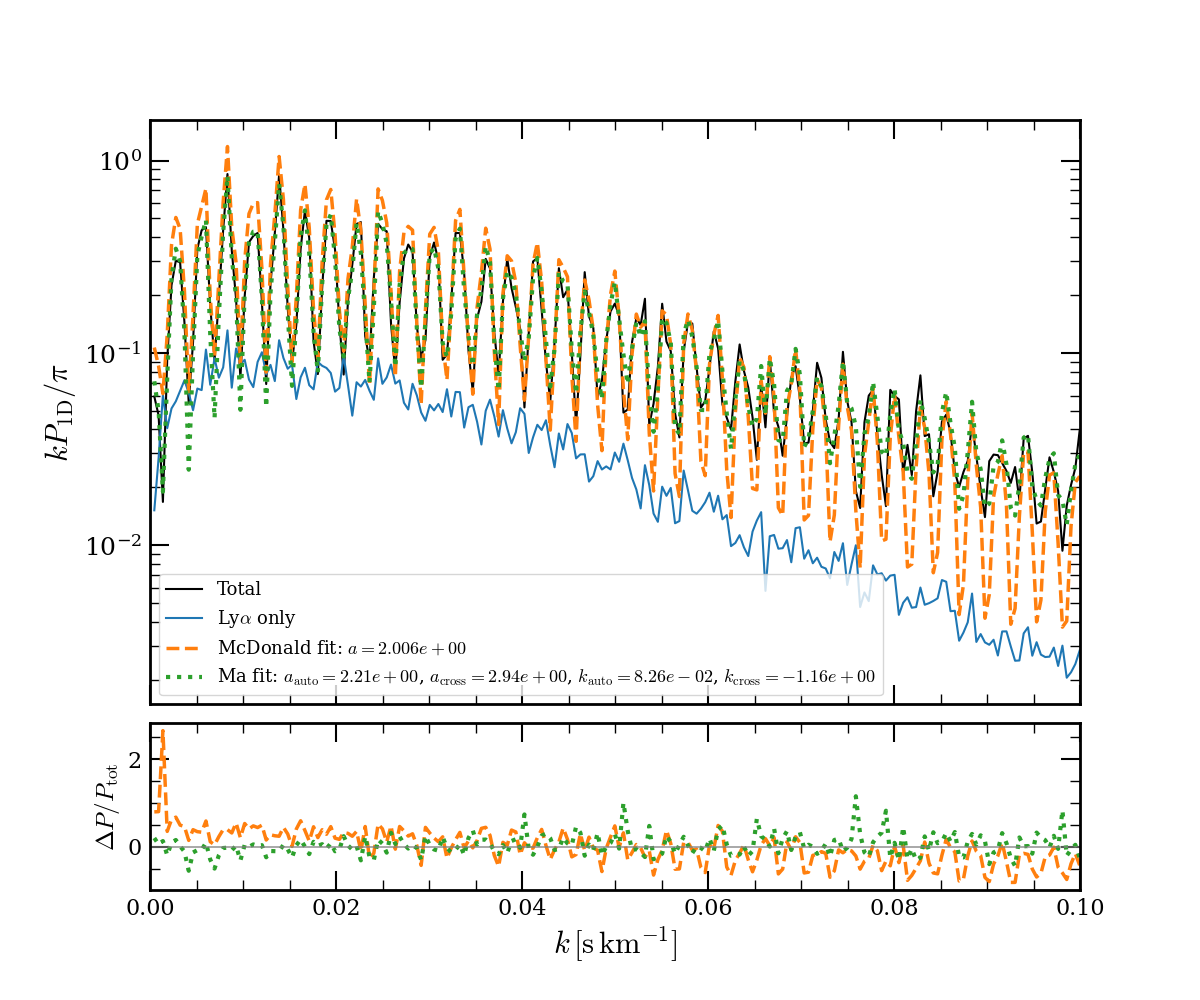

/home/dlopez/tmp/pip-tmp/ipykernel_472006/3675489695.py:77: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


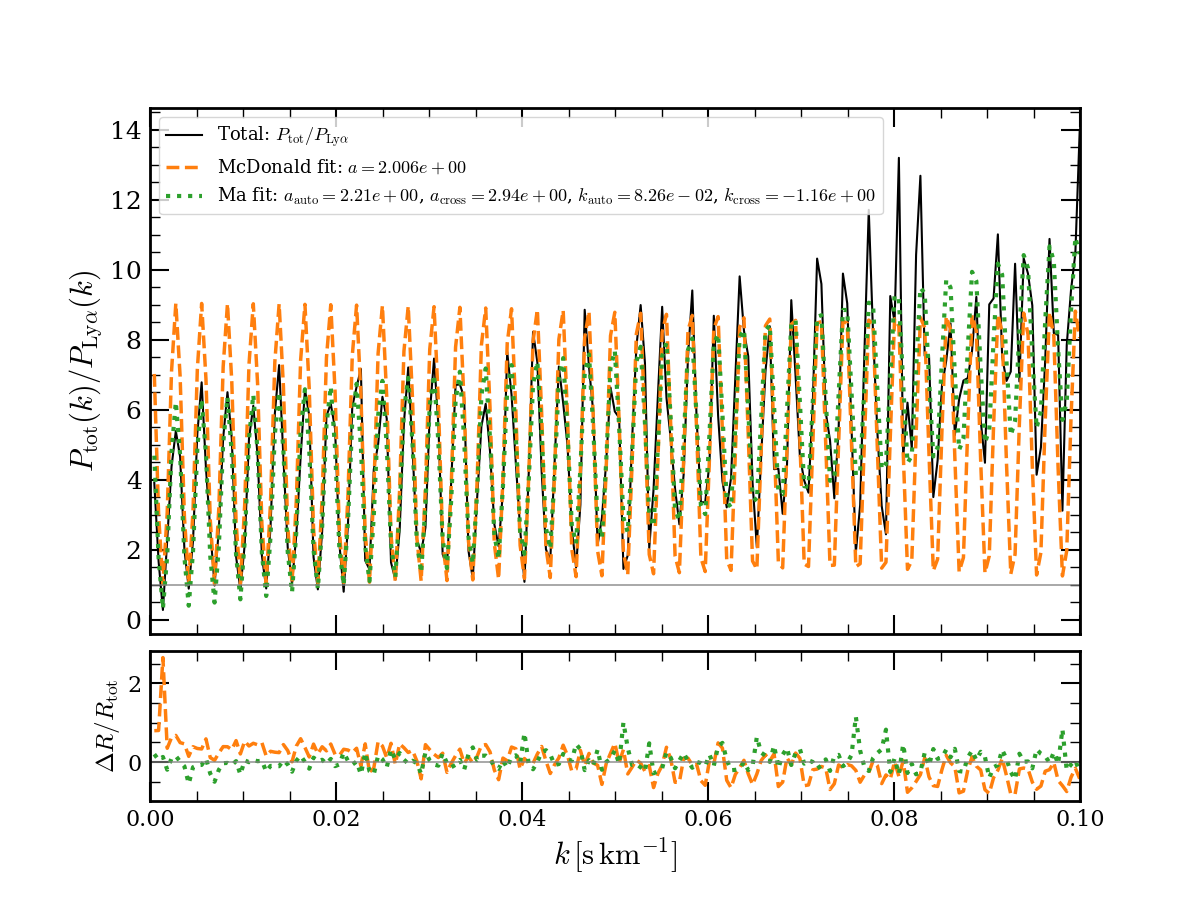

In [27]:
cmap = plt.get_cmap("tab10")

mask = (
    np.isfinite(k) & np.isfinite(p_tot) & np.isfinite(p_lya)
    & np.isfinite(Pk_mcdonald_best) & np.isfinite(Pk_ma_best)
    & (p_tot != 0) & (p_lya > 0)
    & (k > k_fit_range[0]) & (k < k_fit_range[1])
)

ratio_data = p_tot / p_lya
mask_r = mask & np.isfinite(ratio_data) & np.isfinite(ratio_mcdonald_best) & np.isfinite(ratio_ma_best) & (ratio_data != 0)

res_lya = (p_lya - p_tot) / p_tot
res_mcd = (Pk_mcdonald_best - p_tot) / p_tot
res_ma = (Pk_ma_best - p_tot) / p_tot
res_ratio_mcd = (ratio_mcdonald_best - ratio_data) / ratio_data
res_ratio_ma = (ratio_ma_best - ratio_data) / ratio_data

mcd_label = rf"McDonald fit: $a={a_mcd_best:.3e}$"
ma_label = (
    r"Ma fit: "
    rf"$a_{{\rm auto}}={a_auto_best:.2e}$, "
    rf"$a_{{\rm cross}}={a_cross_best:.2e}$, "
    rf"$k_{{\rm auto}}={k_auto_best:.2e}$, "
    rf"$k_{{\rm cross}}={k_cross_best:.2e}$"
)

# ===============================================================
# Plot 1: P1D with residual panel
# ===============================================================

fig, (ax, axr) = plt.subplots(2, 1, figsize=(12, 10), sharex=True, gridspec_kw={"height_ratios": [3.5, 1.0], "hspace": 0.05})

ax.plot(k[mask], p_tot[mask] * k[mask] / np.pi, lw=1.5, color="k", label=r"Total")
ax.plot(k[mask], p_lya[mask] * k[mask] / np.pi, lw=1.5, ls="-", color=cmap(0), label=r"Ly$\alpha$ only")
ax.plot(k[mask], Pk_mcdonald_best[mask] * k[mask] / np.pi, lw=2.5, ls="--", color=cmap(1), label=mcd_label)
ax.plot(k[mask], Pk_ma_best[mask] * k[mask] / np.pi, lw=3.0, ls=":", color=cmap(2), label=ma_label)
ax.set_yscale("log")
ax.set_ylabel(r"$k P_{\rm 1D} / \pi$", fontsize=22)
ax.tick_params(axis="both", labelsize=18)
ax.legend(fontsize=13)

# axr.plot(k[mask], res_lya[mask], lw=1.5, ls="-", color=cmap(0), label=r"Ly$\alpha$")
axr.plot(k[mask], res_mcd[mask], lw=2.5, ls="--", color=cmap(1), label=r"McDonald")
axr.plot(k[mask], res_ma[mask], lw=3.0, ls=":", color=cmap(2), label=r"Ma")
axr.axhline(0.0, lw=1.2, color="0.5", alpha=0.8)
axr.set_xlabel(r"$k\,[{\rm s\,km^{-1}}]$", fontsize=22)
axr.set_ylabel(r"$\Delta P/P_{\rm tot}$", fontsize=18)
axr.set_xlim(k_fit_range)
axr.tick_params(axis="both", labelsize=16)

plt.tight_layout()
plt.show()

# ===============================================================
# Plot 2: P_tot / P_Lya with residual panel
# ===============================================================

fig, (ax, axr) = plt.subplots(2, 1, figsize=(12, 9), sharex=True, gridspec_kw={"height_ratios": [3.5, 1.0], "hspace": 0.05})

ax.plot(k[mask_r], ratio_data[mask_r], lw=1.5, color="k", label=r"Total: $P_{\rm tot}/P_{\rm Ly\alpha}$")
ax.plot(k[mask_r], ratio_mcdonald_best[mask_r], lw=2.5, ls="--", color=cmap(1), label=mcd_label)
ax.plot(k[mask_r], ratio_ma_best[mask_r], lw=3.0, ls=":", color=cmap(2), label=ma_label)
ax.axhline(1.0, lw=1.2, color="0.5", alpha=0.8)
ax.set_ylabel(r"$P_{\rm tot}(k)/P_{\rm Ly\alpha}(k)$", fontsize=22)
ax.tick_params(axis="both", labelsize=18)
ax.legend(fontsize=13)

axr.plot(k[mask_r], res_ratio_mcd[mask_r], lw=2.5, ls="--", color=cmap(1), label=r"McDonald")
axr.plot(k[mask_r], res_ratio_ma[mask_r], lw=3.0, ls=":", color=cmap(2), label=r"Ma")
axr.axhline(0.0, lw=1.2, color="0.5", alpha=0.8)
axr.set_xlabel(r"$k\,[{\rm s\,km^{-1}}]$", fontsize=22)
axr.set_ylabel(r"$\Delta R/R_{\rm tot}$", fontsize=18)
axr.set_xlim(k_fit_range)
axr.tick_params(axis="both", labelsize=16)

plt.tight_layout()
plt.show()


# 3D summary stats

In [28]:
# --- Grid geometry ---

# d_perp: transverse spacing between skewers [cMpc] This comes from your simulation box: L_perp / N_xy where L_perp is the comoving side length and N_xy = sqrt(N_sk)
N_sk  = overflux.total.shape[0]
N_xy  = int(round(N_sk ** 0.5))
d_perp = L_box / N_xy   # e.g. L_perp_cMpc = 20.0 for a 20 cMpc/h box

# --- Build statistics object ---
stats3d = sjx.summary_stats.P3D_xi3D.OverfluxStatistics3D(overflux, dv, d_perp)
ordered_pairs = stats3d.ordered_pairs

2026-06-16 10:36:14,066 - INFO - OverfluxStatistics3D initialized: N_xy=6, N_pix=5000, d_perp=18.4500 cMpc, dv=2.7154 km/s.


# $P3D$

In [29]:
stats3d.compute_p3d()
Pk_binned, kp_centers, kp_edges, k_par, n_modes = stats3d.bin_p3d_kperp(n_kperp_bins=6)
Pk_binned_terms, *_ = stats3d.bin_p3d_kperp(n_kperp_bins=6, Pk3d_input=stats3d.Pk3d_total_from_terms)

2026-06-16 10:36:14,507 - INFO - compute_p3d() done: prefactor=9.2432e+02 [cMpc^2 km/s], shape=(6, 6, 5000), n_pairs=9.


In [30]:
Pk_binned.shape

(6, 5000)

In [31]:
k_par.shape

(5000,)

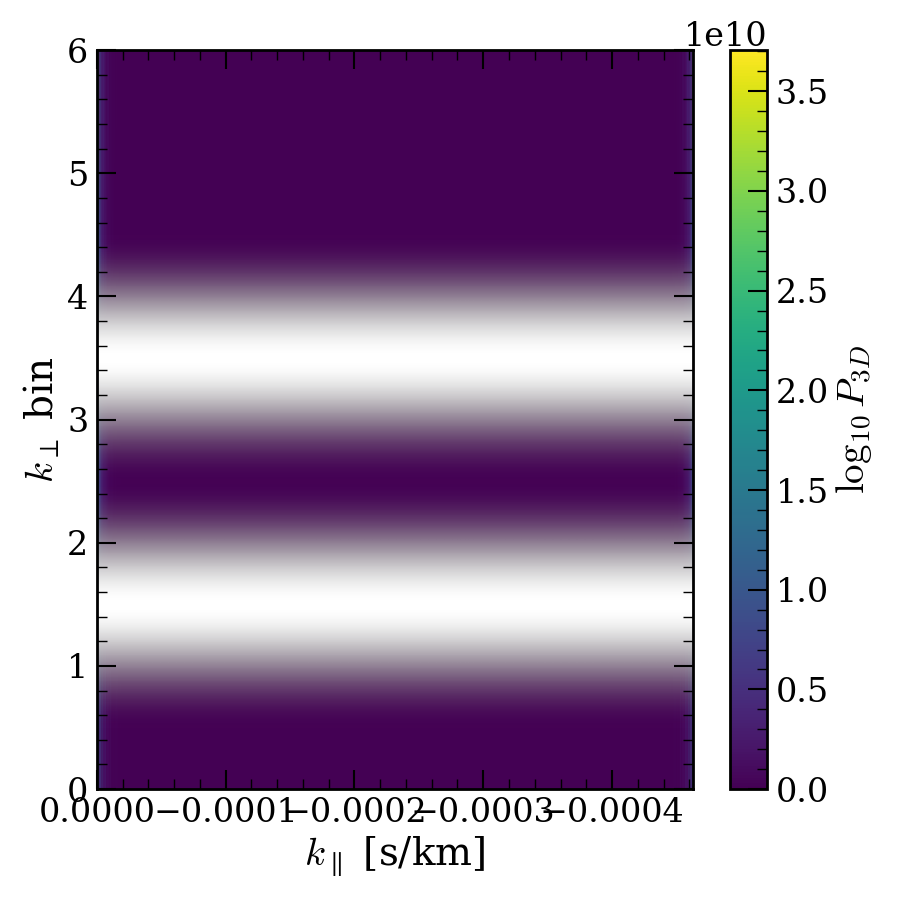

In [32]:
fig, ax = plt.subplots(1, 1, figsize=(9, 9))
im = ax.imshow(Pk_binned, aspect='auto', origin='lower', extent=[k_par[0], k_par[-1], 0, len(kp_centers)])
ax.set_xlabel(r'$k_\parallel$ [s/km]')
ax.set_ylabel(r'$k_\perp$ bin')
plt.colorbar(im, ax=ax, label=r'$\log_{10}P_{3D}$')

plt.tight_layout()

# $\xi3D$

In [33]:
# --- Compute xi3D (calls compute_p3d automatically) ---
stats3d.compute_xi3d()

# Total xi3D: shape (N_xy, N_xy, N_pix), axes (r_x, r_y, pi), all fftshift-centered
xi3d_total              = stats3d.xi3d_total
xi3d_pair               = stats3d.xi3d_pair           # dict {(a,b): (N_xy, N_xy, N_pix)}
xi3d_total_from_terms   = stats3d.xi3d_total_from_terms
r_perp_1d               = stats3d.r_perp_1d           # (N_xy,)  [cMpc]
pi_lags                 = stats3d.pi_lags              # (N_pix,) [km/s]

# --- Bin in r_perp shells ---
xi_binned, r_centers, r_edges, pi_lags, n_pairs = stats3d.bin_xi3d_rperp(n_rperp_bins=100)
# xi_binned: (n_rperp_bins, N_pix)

2026-06-16 10:36:16,173 - INFO - compute_xi3d() done: output shape=(6, 6, 5000), correction=3.2807e-03.


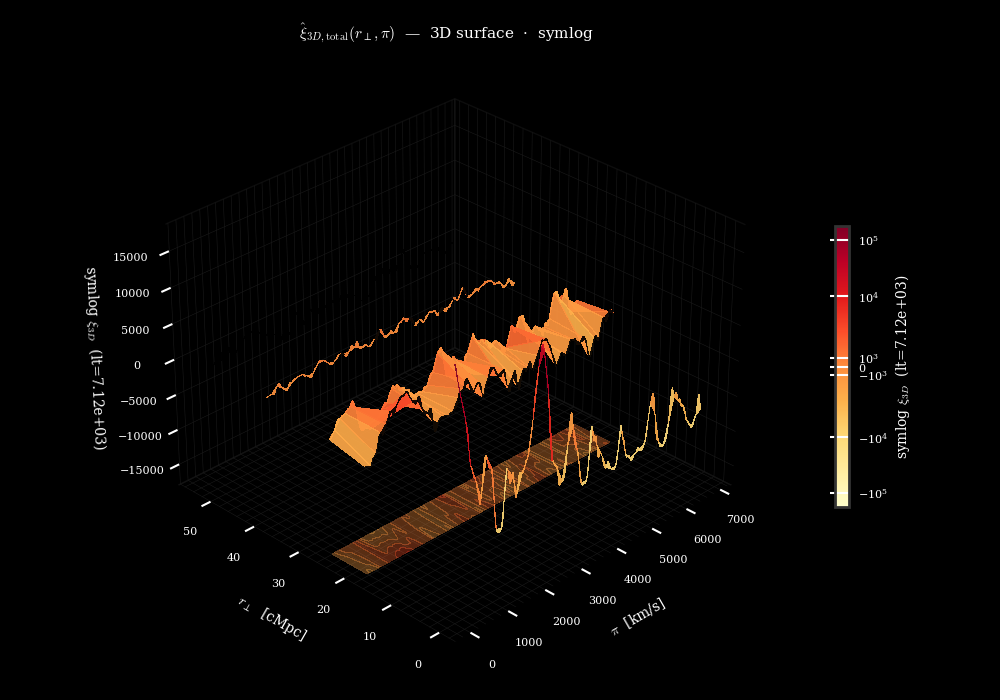

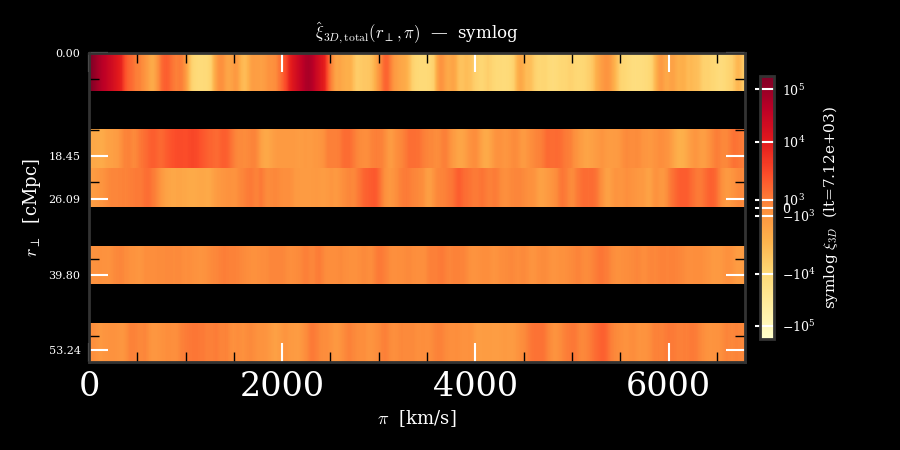

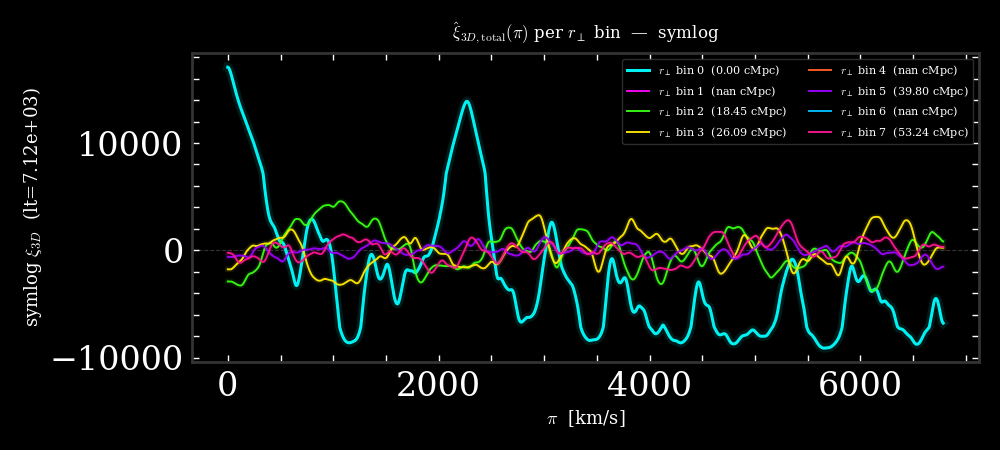

In [34]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.lines import Line2D
from mpl_toolkits.mplot3d import Axes3D

# ── neon palette (mirrors reference script) ──────────────────────────────────
NEON = [
    "#00FFFF","#FF00FF","#39FF14","#FFEA00","#FF5F1F",
    "#9D00FF","#00BFFF","#FF1493","#7FFF00","#FF073A","#00FF7F","#FF3131",
]

# ── shared scale helpers ─────────────────────────────────────────────────────
def make_norm_and_transform(xi_pos, scale, linthresh_frac=0.04):
    """
    Returns (norm, cmap_str, cbar_label, Z_transform_fn).
    Z_transform_fn maps raw xi values to a display-space array (for Fig 3).
    """
    vmax = np.nanmax(np.abs(xi_pos))
    vmax = vmax if vmax > 0 else 1.0

    if scale == "linear":
        norm   = mpl.colors.TwoSlopeNorm(vmin=-vmax, vcenter=0.0, vmax=vmax)
        cmap   = "YlOrRd"          # cyan-white-red in dark mode
        clabel = r"$\xi_{3D}$"
        Ztrans = lambda Z: Z

    elif scale == "log":
        vmin_p = np.nanmin(xi_pos[xi_pos > 0]) if np.any(xi_pos > 0) else 1e-6 * vmax
        norm   = mpl.colors.LogNorm(vmin=vmin_p, vmax=vmax)
        cmap   = "plasma"
        clabel = r"$\log_{10}\,\xi_{3D}$"
        with np.errstate(divide="ignore", invalid="ignore"):
            Ztrans = lambda Z: np.where(Z > 0, np.log10(np.maximum(Z, 1e-15)), np.nan)

    elif scale == "symlog":
        lt   = linthresh_frac * vmax
        norm = mpl.colors.SymLogNorm(linthresh=lt, vmin=-vmax, vmax=vmax, base=10)
        cmap = "YlOrRd"
        clabel = rf"symlog $\xi_{{3D}}$  (lt={lt:.2e})"
        def Ztrans(Z):
            lt_ = lt
            s, a = np.sign(Z), np.abs(Z)
            return s * np.where(a <= lt_, a, lt_ + lt_ * np.log10(np.maximum(a / lt_, 1.0)))
    else:
        raise ValueError(f"scale must be 'linear', 'log', or 'symlog'; got '{scale}'")

    return norm, cmap, clabel, Ztrans


# ── data ─────────────────────────────────────────────────────────────────────
N_RPERP_BINS   = 8
SCALE          = "symlog"    # ← change here: 'linear' | 'log' | 'symlog'
LINTHRESH_FRAC = 0.04

stats3d.compute_xi3d()
xi_binned, r_centers, r_edges, pi_lags, n_pairs = stats3d.bin_xi3d_rperp(N_RPERP_BINS)

half    = len(pi_lags) // 2
pi_pos  = pi_lags[half:]          # [0, L_Λ/2]
xi_pos  = xi_binned[:, half:]     # (N_bins, N_pix/2)

norm, cmap_str, clabel, Ztrans = make_norm_and_transform(xi_pos, SCALE, LINTHRESH_FRAC)


# ── Figure 1:  heatmap ───────────────────────────────────────────────────────
fig1, ax1 = plt.subplots(figsize=(9, 4.5), facecolor="black")
ax1.set_facecolor("black")

im = ax1.imshow(
    xi_pos,
    aspect="auto", origin="upper",
    extent=[pi_pos[0], pi_pos[-1], r_edges[-1], r_edges[0]],
    norm=norm, cmap=cmap_str,
    interpolation="nearest",
)
cb = fig1.colorbar(im, ax=ax1, pad=0.02, shrink=0.85)
cb.set_label(clabel, color="white", fontsize=11)
cb.ax.yaxis.set_tick_params(color="white")
plt.setp(cb.ax.yaxis.get_ticklabels(), color="white", fontsize=9)
cb.outline.set_edgecolor("#333")

ax1.set_xlabel(r"$\pi$  [km/s]", fontsize=13, color="white")
ax1.set_ylabel(r"$r_\perp$  [cMpc]", fontsize=13, color="white")
ax1.set_yticks(r_centers)
ax1.set_yticklabels([f"{r:.2f}" for r in r_centers], fontsize=8, color="white")
ax1.xaxis.set_tick_params(colors="white"); ax1.yaxis.set_tick_params(colors="white")
for sp in ax1.spines.values(): sp.set_edgecolor("#333")
ax1.set_title(
    rf"$\hat{{\xi}}_{{3D,\mathrm{{total}}}}(r_\perp,\pi)$  —  {SCALE}",
    color="white", fontsize=12, pad=10
)
fig1.tight_layout()


# ── Figure 2:  line profiles ─────────────────────────────────────────────────
fig2, ax2 = plt.subplots(figsize=(10, 4.5), facecolor="black")
ax2.set_facecolor("black")

for b in range(N_RPERP_BINS):
    raw = xi_pos[b]
    y   = Ztrans(raw)
    lw  = 2.2 if b == 0 else 1.4
    c   = NEON[b % len(NEON)]
    ax2.plot(pi_pos, y,  color=c, lw=lw*3, alpha=0.10, zorder=2)   # glow
    ax2.plot(pi_pos, y,  color=c, lw=lw,   alpha=0.95, zorder=3,
             label=rf"$r_\perp$ bin {b}  ({r_centers[b]:.2f} cMpc)")

ax2.axhline(0, color="#333", lw=0.8, ls="--", zorder=1)
ax2.set_xlabel(r"$\pi$  [km/s]", fontsize=13, color="white")
ax2.set_ylabel(clabel, fontsize=13, color="white")
ax2.tick_params(colors="white", which="both", direction="in",
                top=True, right=True, length=5, width=1.0)
for sp in ax2.spines.values(): sp.set_edgecolor("#333")
ax2.set_title(
    rf"$\hat{{\xi}}_{{3D,\mathrm{{total}}}}(\pi)$ per $r_\perp$ bin  —  {SCALE}",
    color="white", fontsize=12, pad=10
)
leg = ax2.legend(fontsize=8, ncol=2, loc="upper right",
                 facecolor="black", edgecolor="#333", framealpha=0.9)
for t in leg.get_texts(): t.set_color("white")
fig2.tight_layout()


# ── Figure 3:  3D surface ─────────────────────────────────────────────────────
# Key fixes:
#   linewidth=0  → no edge artefacts
#   antialiased=False  → no white fringing
#   shade=False  → pure colormap, no matplotlib lighting wash-out
#   facecolors=cmap(norm(Z))  → direct colour mapping without double-application
fig3 = plt.figure(figsize=(10, 7), facecolor="black")
ax3  = fig3.add_subplot(111, projection="3d", facecolor="black")

PI_grid, R_grid = np.meshgrid(pi_pos, r_centers)
Z_raw           = xi_pos
Z_disp          = Ztrans(Z_raw.copy())

# Build face colours from the original raw norm (linear/log/symlog)
cmap_obj   = plt.get_cmap(cmap_str)
face_colors = cmap_obj(norm(Z_raw))           # RGBA, shape (N_bins, N_pix/2, 4)

surf = ax3.plot_surface(
    PI_grid, R_grid, Z_disp,
    facecolors=face_colors,
    linewidth=0,                               # ← eliminates white edge lines
    antialiased=False,                         # ← no fringing
    shade=False,                               # ← pure colormap, no lighting
    alpha=0.92,
)

# Contour projected on the floor for depth cue
vmax_d = np.nanmax(np.abs(Z_disp[np.isfinite(Z_disp)]))
ax3.contourf(
    PI_grid, R_grid, Z_disp,
    zdir="z", offset=-vmax_d * 1.05,
    levels=20, cmap=cmap_str, norm=norm, alpha=0.35,
)
ax3.set_zlim(-vmax_d * 1.05, vmax_d * 1.1)

# Coloubar
m = mpl.cm.ScalarMappable(cmap=cmap_str, norm=norm)
m.set_array([])
cb3 = fig3.colorbar(m, ax=ax3, shrink=0.45, pad=0.08)
cb3.set_label(clabel, color="white", fontsize=10)
cb3.ax.yaxis.set_tick_params(color="white")
plt.setp(cb3.ax.yaxis.get_ticklabels(), color="white", fontsize=8)
cb3.outline.set_edgecolor("#333")

# Dark pane styling (mirrors reference script's _dark_3d_style)
ax3.set_facecolor("black")
for axis in [ax3.xaxis, ax3.yaxis, ax3.zaxis]:
    axis.pane.fill = False
    axis.pane.set_edgecolor("#1a1a1a")
    axis.label.set_color("white")
    try:
        axis._axinfo["grid"]["linewidth"] = 0.4
        axis._axinfo["grid"]["color"]     = "#1a1a1a"
    except Exception:
        pass

ax3.tick_params(colors="white", labelsize=8, length=4)
ax3.set_xlabel(r"$\pi$  [km/s]",      fontsize=10, labelpad=10, color="white")
ax3.set_ylabel(r"$r_\perp$  [cMpc]",  fontsize=10, labelpad=10, color="white")
ax3.set_zlabel(clabel,                 fontsize=10, labelpad=10, color="white")
ax3.set_title(
    rf"$\hat{{\xi}}_{{3D,\mathrm{{total}}}}(r_\perp,\pi)$  —  3D surface  ·  {SCALE}",
    color="white", fontsize=11, pad=12
)
ax3.view_init(elev=30, azim=225)
fig3.tight_layout()
plt.show()